<a href="https://colab.research.google.com/github/valentinabenitez-crypto/Cargar-COLLAB/blob/main/Parte_A_1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ENTREGA 1 - PARTE A
# Carga de datos desde GitHub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dirección del repositorio (corregida)
repo = "https://raw.githubusercontent.com/valentinabenitez-crypto/Cargar-COLLAB/main/Datos/"

# Cargar archivos
llenado = pd.read_csv(repo + "calidad_llenado.csv")
atributos = pd.read_csv(repo + "calidad_atributos.csv")
especificaciones = pd.read_csv(repo + "especificaciones_calidad.csv")
maestro = pd.read_csv(repo + "maestro_sku.csv")
demanda = pd.read_csv(repo + "demanda_semanal.csv")

# Verificar la carga
print("Archivos cargados correctamente")

print("Calidad llenado:", llenado.shape)
print("Calidad atributos:", atributos.shape)
print("Especificaciones:", especificaciones.shape)
print("Maestro SKU:", maestro.shape)
print("Demanda semanal:", demanda.shape)

display(llenado.head())

Archivos cargados correctamente
Calidad llenado: (4200, 10)
Calidad atributos: (210, 8)
Especificaciones: (3, 6)
Maestro SKU: (9, 13)
Demanda semanal: (1404, 10)


,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


Exploración y diagnóstico de los datos: comprobar que las mediciones de llenado estén correctamente registradas antes de construir las cartas de control.


In [3]:
# BLOQUE 2: EXPLORACIÓN Y DIAGNÓSTICO DE DATOS

# Revisar las primeras 5 filas
print(llenado.head())

# Revisar cantidad de filas y columnas
print("Dimensiones:")
print(llenado.shape)

# Revisar nombres y tipos de columnas
print("Información general:")
llenado.info()

# Obtener estadísticas descriptivas
print("Estadísticas descriptivas:")
print(llenado.describe())

   subgrupo       fecha  semana_registro      turno linea      sku  formato_L  \
0         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
1         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
2         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
3         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
4         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   

    hora  n_obs  volumen_mL  
0  06:00      1      500.86  
1  06:00      2      502.11  
2  06:00      3      503.12  
3  06:00      4      502.60  
4  06:00      5      499.11  
Dimensiones:
(4200, 10)
Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subgrupo         4200 non-null   int64  
 1   fecha            4200 non-null   objec

 Validación de datos
Antes de realizar el análisis estadístico del proceso de llenado, se realiza una validación inicial de la base de datos con el objetivo de identificar posibles problemas que puedan afectar los resultados. Para esto, se revisa la existencia de valores faltantes, registros duplicados, consistencia en el tamaño de los subgrupos de medición y distribución de las observaciones según línea de producción, formato y turno.
Esta etapa permite asegurar que los datos utilizados posteriormente para la construcción de cartas de control representen adecuadamente el comportamiento del proceso productivo.

In [4]:
#BLOQUE 3 validación de datos
#1
# Revisar valores faltantes

print("Valores faltantes por columna:")
print(llenado.isnull().sum())

#2
#Revisar registros duplicados

print("Cantidad de filas duplicadas:")
print(llenado.duplicated().sum())

#3
# Revisar tamaño de los subgrupos

cantidad_subgrupo = llenado.groupby("subgrupo").size()

print("Cantidad de mediciones por subgrupo:")
print(cantidad_subgrupo.value_counts())

#4
# Identificar subgrupos que no tienen 5 observaciones

subgrupos_incorrectos = cantidad_subgrupo[cantidad_subgrupo != 5]

print("Subgrupos con cantidad distinta de 5:")
print(subgrupos_incorrectos)

# 5
#Revisar cantidad de mediciones por línea

print("Mediciones por línea:")
print(llenado["linea"].value_counts())


#6
# Revisar cantidad por formato

print("\nMediciones por formato:")
print(llenado["formato_L"].value_counts())


#7
# Revisar cantidad por turno

print("\nMediciones por turno:")
print(llenado["turno"].value_counts())

Valores faltantes por columna:
subgrupo           0
fecha              0
semana_registro    0
turno              0
linea              0
sku                0
formato_L          0
hora               0
n_obs              0
volumen_mL         0
dtype: int64
Cantidad de filas duplicadas:
0
Cantidad de mediciones por subgrupo:
5    840
Name: count, dtype: int64
Subgrupos con cantidad distinta de 5:
Series([], dtype: int64)
Mediciones por línea:
linea
L2    3000
L1    1200
Name: count, dtype: int64

Mediciones por formato:
formato_L
3.0    1560
1.5    1440
0.5    1200
Name: count, dtype: int64

Mediciones por turno:
turno
A (06-14)    1600
B (14-22)    1600
C (22-06)    1000
Name: count, dtype: int64


1. "La base de datos de llenado no presenta valores faltantes, por lo que todas las observaciones pueden ser consideradas en el análisis estadístico posterior."
2. "No se identificaron registros duplicados, evitando que algunas mediciones tengan una influencia artificialmente mayor dentro del análisis."
3. Todos los subgrupos contienen cinco observaciones, cumpliendo la estructura necesaria para aplicar cartas de control X̄–R.
4. No se encontraron subgrupos con tamaños incorrectos, por lo que no fue necesario realizar ajustes en la estructura de los datos.
5. La línea L2 concentra la mayor cantidad de mediciones (3000), mientras que L1 posee 1200 observaciones. El análisis posterior considerará cada línea por separado.
6. Se identificaron tres formatos de producción (0,5 L, 1,5 L y 3,0 L). Debido a sus diferentes volúmenes nominales, serán analizados de manera independiente.
7. Se cuenta con registros de los tres turnos de operación, permitiendo evaluar posteriormente si existen diferencias asociadas al turno de producción.

PREPARACIÓN DE DATOS CARTAS X-R
Para construir las cartas de control X̄–R, se agrupan las mediciones individuales en subgrupos racionales de cinco observaciones. Para cada subgrupo se calcula el promedio del volumen y el rango, permitiendo evaluar tanto el nivel central del proceso como su variabilidad.

In [5]:
#BLOQUE 4 Preparación de datos para cartas X-R
# Crear tabla con promedio y rango por subgrupo

datos_control = llenado.groupby("subgrupo").agg(media_volumen=("volumen_mL", "mean"),
    rango_volumen=("volumen_mL", lambda x: x.max() - x.min()),
    linea=("linea", "first"),
    formato_L=("formato_L", "first"),
    turno=("turno", "first")
).reset_index()


# Mostrar primeros resultados

datos_control.head()


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno
0,1,501.560,4.01,L1,0.5,A (06-14)
1,2,501.752,5.17,L1,0.5,A (06-14)
2,3,503.630,4.13,L1,0.5,A (06-14)
3,4,503.172,2.10,L1,0.5,A (06-14)
4,5,503.396,8.49,L1,0.5,B (14-22)


Se transformaron las mediciones individuales en subgrupos racionales de cinco observaciones, calculando para cada uno la media y el rango del volumen de llenado. Esta estructura permitirá construir las cartas X̄–R, evaluando tanto el nivel promedio del proceso como su variabilidad.

 Separación de procesos por línea y formato
Y escribe:
Debido a que el proceso de llenado presenta diferentes líneas de producción y formatos de producto, los análisis estadísticos se realizarán de manera independiente para cada combinación línea-formato. Esto permite comparar procesos equivalentes y evitar distorsiones producto de diferencias en los volúmenes nominales.

In [6]:
#BLOQUE 5 Separación de procesos para análisis estadístico
# Revisar combinaciones de línea y formato

datos_control[["linea", "formato_L"]].drop_duplicates()

# Separar procesos por línea y formato

proceso_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5)
]

proceso_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5)
]

proceso_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0)
]


print("L1 - 0.5 L:", proceso_L1_05.shape)
print("L2 - 1.5 L:", proceso_L2_15.shape)
print("L2 - 3.0 L:", proceso_L2_30.shape)

L1 - 0.5 L: (240, 6)
L2 - 1.5 L: (288, 6)
L2 - 3.0 L: (312, 6)


Se identificaron tres combinaciones de línea y formato, las cuales fueron separadas para realizar el análisis estadístico de manera independiente y evitar mezclar procesos con distintos volúmenes nominales.
¿Qué significa el resultado (240, 6)?
- 240: cantidad de subgrupos correspondientes a la línea L1 y formato 0,5 L.
- 6: cantidad de columnas de nuestra tabla datos_control.

In [7]:
#BLOQUE 6 : COMPROBACIONES
# Agregar la semana de cada subgrupo a datos_control

semana_subgrupo = llenado[
    ["subgrupo", "semana_registro"]
].drop_duplicates()

datos_control = pd.merge(
    datos_control,
    semana_subgrupo,
    on="subgrupo",
    how="left"
)

display(datos_control.head())

,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro
0,1,501.560,4.01,L1,0.5,A (06-14),1
1,2,501.752,5.17,L1,0.5,A (06-14),1
2,3,503.630,4.13,L1,0.5,A (06-14),1
3,4,503.172,2.10,L1,0.5,A (06-14),1
4,5,503.396,8.49,L1,0.5,B (14-22),1


In [8]:
# Cantidad de subgrupos por semana y proceso

print(
    datos_control.groupby(
        ["linea", "formato_L", "semana_registro"]
    ).size()
)

linea  formato_L  semana_registro
L1     0.5        1                  24
                  2                  24
                  3                  24
                  4                  24
                  5                  24
                  6                  24
                  7                  24
                  8                  24
                  9                  24
                  10                 24
L2     1.5        1                  20
                  2                  32
                  3                  28
                  4                  40
                  5                  16
                  6                  24
                  7                  32
                  8                  24
                  9                  36
                  10                 36
       3.0        1                  40
                  2                  28
                  3                  32
                  4                  20
      

In [9]:
# BLOQUE 7: DEFINICIÓN DE FASE I Y FASE II

datos_control["fase"] = "II"

datos_control.loc[
    datos_control["semana_registro"].isin([1, 2]),
    "fase"
] = "I"

print(datos_control["fase"].value_counts())

display(datos_control.head())

fase
II    672
I     168
Name: count, dtype: int64


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
0,1,501.560,4.01,L1,0.5,A (06-14),1,I
1,2,501.752,5.17,L1,0.5,A (06-14),1,I
2,3,503.630,4.13,L1,0.5,A (06-14),1,I
3,4,503.172,2.10,L1,0.5,A (06-14),1,I
4,5,503.396,8.49,L1,0.5,B (14-22),1,I


In [10]:
# FASE I DEL PROCESO L1 - 0.5 L

fase1_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["fase"] == "I")
]

print("Cantidad de subgrupos en Fase I:")
print(fase1_L1_05.shape[0])

Cantidad de subgrupos en Fase I:
48


In [11]:
# Promedio de las medias de los subgrupos
media_medias = fase1_L1_05["media_volumen"].mean()

# Promedio de los rangos de los subgrupos
media_rangos = fase1_L1_05["rango_volumen"].mean()

print("Media de medias:", media_medias)
print("Media de rangos:", media_rangos)

Media de medias: 502.643625
Media de rangos: 4.749583333333333


Obtenemos desde las tablas impartidas en clases de calidad 2 las constantes # Constantes para cartas X barra - R con subgrupos de tamaño n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

In [12]:
# Constantes para n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

# Límites de la carta R
LC_R = media_rangos
LSC_R = D4 * media_rangos
LIC_R = D3 * media_rangos

# Límites de la carta X barra
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

print("Carta R")
print("LIC:", LIC_R)
print("LC:", LC_R)
print("LSC:", LSC_R)

print("\nCarta X barra")
print("LIC:", LIC_X)
print("LC:", LC_X)
print("LSC:", LSC_X)

Carta R
LIC: 0.0
LC: 4.749583333333333
LSC: 10.040619166666666

Carta X barra
LIC: 499.90311541666665
LC: 502.643625
LSC: 505.3841345833333


In [13]:
# Revisar puntos fuera de los límites en la carta R - Fase I

fuera_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Subgrupos fuera de control en la carta R:")
display(fuera_R)

Subgrupos fuera de control en la carta R:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
91,92,502.946,10.06,L1,0.5,B (14-22),2,I


In [14]:
# Revisar las mediciones originales del subgrupo 92

subgrupo_92 = llenado[
    llenado["subgrupo"] == 92
]

display(subgrupo_92)

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
455,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,1,503.56
456,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,2,503.12
457,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,3,506.54
458,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,4,505.03
459,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,5,496.48


Ahora tenemos que seguir investigando porque hay ese valor en este subgrupo por lo que iniciaremos una búsqueda de que salio mal, primero veremos los subgrupos cercanos para tener mas info

In [15]:
# Revisar subgrupos cercanos al 92

vecinos_92 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["subgrupo"] >= 88) &
    (datos_control["subgrupo"] <= 96)
]

display(
    vecinos_92[
        ["subgrupo", "media_volumen", "rango_volumen",
         "turno", "semana_registro"]
    ]
)

,subgrupo,media_volumen,rango_volumen,turno,semana_registro
87,88,503.312,1.87,A (06-14),2
88,89,502.768,6.72,B (14-22),2
89,90,502.888,6.26,B (14-22),2
90,91,503.330,5.80,B (14-22),2
91,92,502.946,10.06,B (14-22),2
92,93,501.440,5.88,A (06-14),2
93,94,503.434,5.98,A (06-14),2
94,95,501.722,4.17,A (06-14),2
95,96,502.652,4.58,A (06-14),2


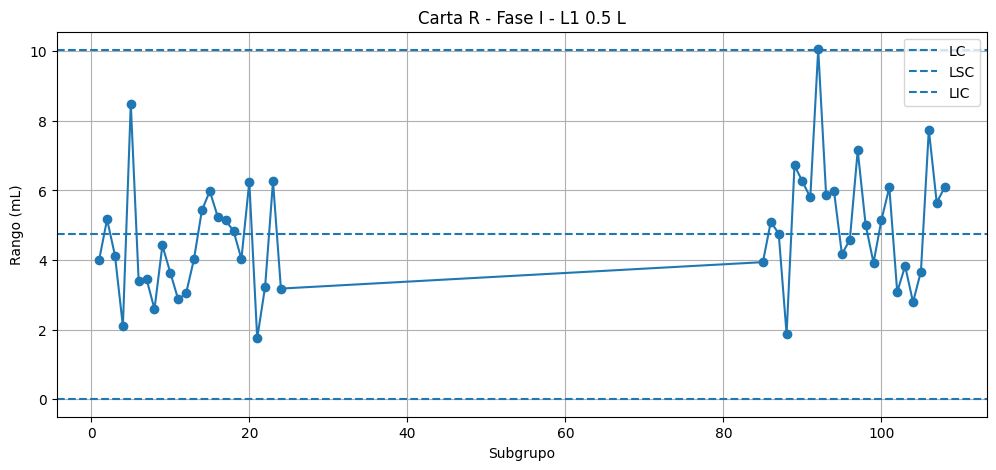

In [16]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["subgrupo"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [17]:
# Crear orden consecutivo para los subgrupos de Fase I
fase1_L1_05 = fase1_L1_05.copy()

fase1_L1_05["orden"] = range(1, len(fase1_L1_05) + 1)

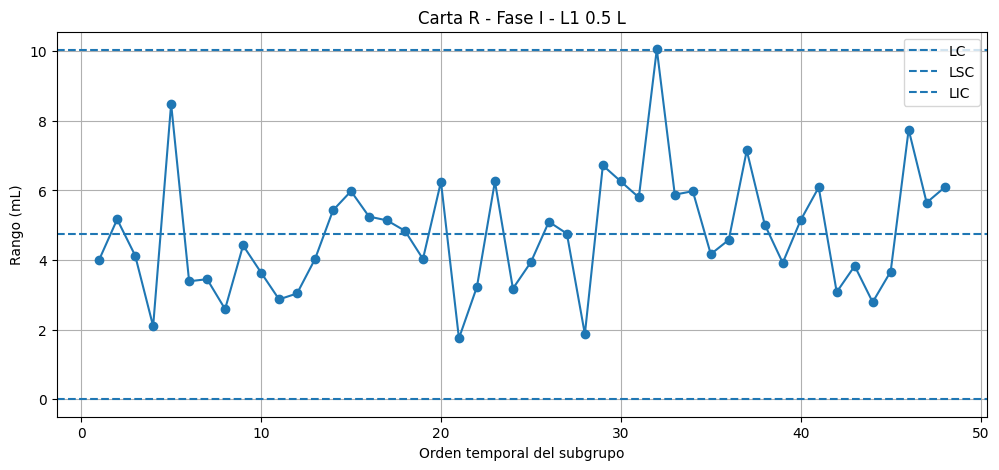

In [18]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["orden"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Orden temporal del subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [19]:
# Regla 1: punto fuera de los límites de control

regla1_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Regla 1 - Puntos fuera de los límites:")
display(regla1_R)

Regla 1 - Puntos fuera de los límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
91,92,502.946,10.06,L1,0.5,B (14-22),2,I,32


Se optó por aplicar un conjunto acotado de reglas de Nelson, evitando mezclar criterios de distintos sistemas y reduciendo el riesgo de falsas alarmas. Se consideraron tres patrones principales: puntos fuera de los límites de control, rachas prolongadas al mismo lado de la línea central y tendencias sostenidas crecientes o decrecientes. Esta selección permite detectar tanto señales extremas como comportamientos no aleatorios del proceso, manteniendo el análisis consistente con lo revisado en clases. 2_Calidad_II

In [20]:
# Regla 2 de Nelson:
# 9 puntos consecutivos al mismo lado de la línea central

valores_R = fase1_L1_05["rango_volumen"].tolist()
subgrupos_R = fase1_L1_05["subgrupo"].tolist()

senales_regla2 = []

for i in range(len(valores_R) - 8):

    grupo = valores_R[i:i+9]

    todos_arriba = all(valor > LC_R for valor in grupo)
    todos_abajo = all(valor < LC_R for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_regla2.append(subgrupos_R[i:i+9])

print("Regla 2 - 9 puntos consecutivos al mismo lado de LC:")
print(senales_regla2)

Regla 2 - 9 puntos consecutivos al mismo lado de LC:
[]


In [21]:
# Tendencia de 6 puntos consecutivos en la carta R

senales_tendencia_R = []

for i in range(len(valores_R) - 5):

    grupo = valores_R[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_R.append(
            subgrupos_R[i:i+6]
        )

print("Tendencias sostenidas detectadas en R:")
print(senales_tendencia_R)

Tendencias sostenidas detectadas en R:
[]


límites

In [22]:
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

In [23]:
fuera_X = fase1_L1_05[
    (fase1_L1_05["media_volumen"] > LSC_X) |
    (fase1_L1_05["media_volumen"] < LIC_X)
]

print("Subgrupos fuera de control en carta X barra:")
display(fuera_X)

Subgrupos fuera de control en carta X barra:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


In [24]:
valores_X = fase1_L1_05["media_volumen"].tolist()
subgrupos_X = fase1_L1_05["subgrupo"].tolist()

In [25]:
senales_9_X = []

for i in range(len(valores_X) - 8):

    grupo = valores_X[i:i+9]

    todos_arriba = all(valor > LC_X for valor in grupo)
    todos_abajo = all(valor < LC_X for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_9_X.append(subgrupos_X[i:i+9])

print("9 puntos consecutivos al mismo lado de LC:")
print(senales_9_X)

9 puntos consecutivos al mismo lado de LC:
[]


Tendencia

In [26]:
senales_tendencia_X = []

for i in range(len(valores_X) - 5):

    grupo = valores_X[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_X.append(
            subgrupos_X[i:i+6]
        )

print("Tendencias sostenidas en X barra:")
print(senales_tendencia_X)

Tendencias sostenidas en X barra:
[]


La carta \(\bar X\) no presentó señales bajo ninguna de las tres reglas seleccionadas. La carta \(R\) presentó únicamente una señal aislada en el subgrupo 92, con \(R=10,06\) mL frente a un LSC de aproximadamente \(10,04\) mL. No se detectaron rachas ni tendencias sostenidas.

In [27]:
def analizar_fase1(datos_control, linea, formato):

    # Filtrar proceso y Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ].copy()

    # Orden temporal
    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Constantes para n = 5
    A2 = 0.577
    D3 = 0
    D4 = 2.114

    # -------------------------
    # Límites de control
    # -------------------------

    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Carta R
    LC_R = media_rangos
    LIC_R = D3 * media_rangos
    LSC_R = D4 * media_rangos

    # Carta X barra
    LC_X = media_medias
    LIC_X = media_medias - A2 * media_rangos
    LSC_X = media_medias + A2 * media_rangos

    print("PROCESO:", linea, "-", formato, "L")
    print("Cantidad de subgrupos:", len(datos))

    print("\nCarta R")
    print("LIC:", LIC_R)
    print("LC:", LC_R)
    print("LSC:", LSC_R)

    print("\nCarta X barra")
    print("LIC:", LIC_X)
    print("LC:", LC_X)
    print("LSC:", LSC_X)


    # =====================================================
    # CARTA R
    # =====================================================

    valores_R = datos["rango_volumen"].tolist()
    subgrupos_R = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_R = datos[
        (datos["rango_volumen"] > LSC_R) |
        (datos["rango_volumen"] < LIC_R)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_R = []

    for i in range(len(valores_R) - 8):

        grupo = valores_R[i:i+9]

        todos_arriba = all(valor > LC_R for valor in grupo)
        todos_abajo = all(valor < LC_R for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_R.append(subgrupos_R[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_R = []

    for i in range(len(valores_R) - 5):

        grupo = valores_R[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_R.append(subgrupos_R[i:i+6])


    # =====================================================
    # CARTA X BARRA
    # =====================================================

    valores_X = datos["media_volumen"].tolist()
    subgrupos_X = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_X = datos[
        (datos["media_volumen"] > LSC_X) |
        (datos["media_volumen"] < LIC_X)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_X = []

    for i in range(len(valores_X) - 8):

        grupo = valores_X[i:i+9]

        todos_arriba = all(valor > LC_X for valor in grupo)
        todos_abajo = all(valor < LC_X for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_X.append(subgrupos_X[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_X = []

    for i in range(len(valores_X) - 5):

        grupo = valores_X[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_X.append(subgrupos_X[i:i+6])


    # -------------------------
    # Mostrar resultados
    # -------------------------

    print("\n--- SEÑALES CARTA R ---")
    print("Fuera de límites:")
    display(fuera_R)

    print("9 puntos al mismo lado:")
    print(senales_9_R)

    print("Tendencias de 6 puntos:")
    print(tendencia_R)


    print("\n--- SEÑALES CARTA X BARRA ---")
    print("Fuera de límites:")
    display(fuera_X)

    print("9 puntos al mismo lado:")
    print(senales_9_X)

    print("Tendencias de 6 puntos:")
    print(tendencia_X)


    # -------------------------
    # Gráfico R
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["rango_volumen"],
        marker="o"
    )

    plt.axhline(LC_R, linestyle="--", label="LC")
    plt.axhline(LSC_R, linestyle="--", label="LSC")
    plt.axhline(LIC_R, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Rango del volumen (mL)")
    plt.title("Carta R - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()


    # -------------------------
    # Gráfico X barra
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["media_volumen"],
        marker="o"
    )

    plt.axhline(LC_X, linestyle="--", label="LC")
    plt.axhline(LSC_X, linestyle="--", label="LSC")
    plt.axhline(LIC_X, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Media del volumen (mL)")
    plt.title("Carta X barra - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()

PROCESO: L2 - 1.5 L
Cantidad de subgrupos: 52

Carta R
LIC: 0.0
LC: 11.658076923076937
LSC: 24.645174615384644

Carta X barra
LIC: 1497.7299819230768
LC: 1504.4566923076923
LSC: 1511.1834026923077

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
32,33,1505.642,25.95,L2,1.5,C (22-06),1,I,1


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
128,129,1513.752,9.26,L2,1.5,C (22-06),2,I,29


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[158, 159, 160, 165, 166, 167]]


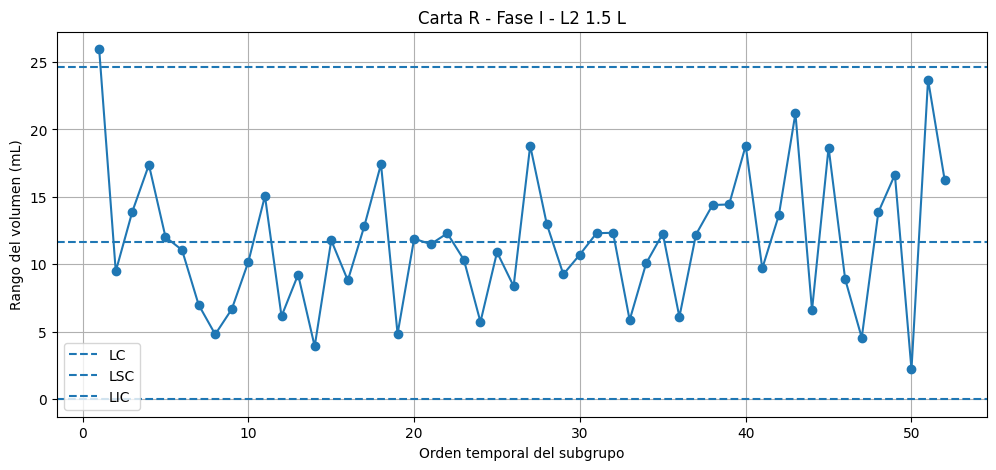

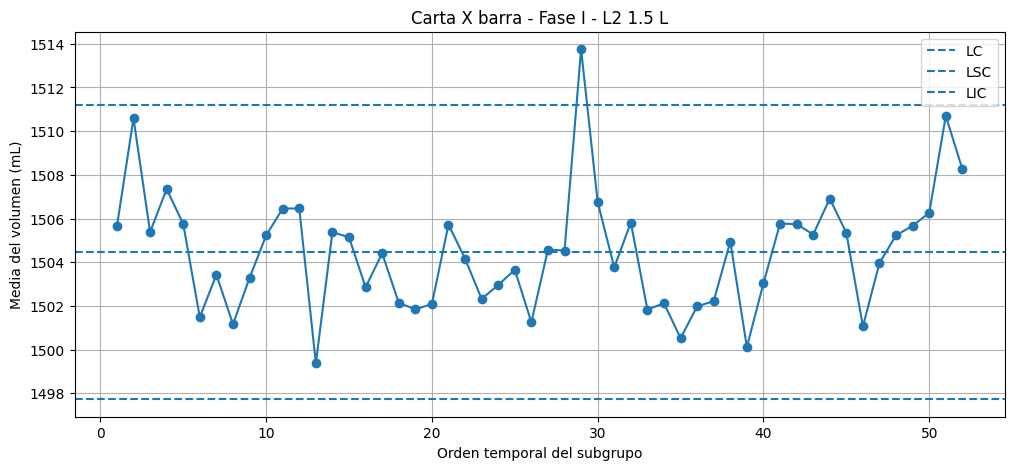

In [28]:
analizar_fase1(datos_control, "L2", 1.5)

La carta \(R\) muestra una señal puntual de variabilidad: el subgrupo 33 tiene \(R=25,95\) mL, superior al \(LSC_R=24,645\) mL. En cambio, la carta \(\bar X\) tiene dos tipos de señales: el subgrupo 129 está directamente sobre el límite superior, y además existe una secuencia de seis medias consecutivas con tendencia.

In [29]:
# Crear nuevamente la Fase I de L2 - 1.5 L
fase1_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_15 = fase1_L2_15.sort_values("subgrupo")
fase1_L2_15["orden"] = range(1, len(fase1_L2_15) + 1)


# Subgrupos que presentaron señales
subgrupos_senal_15 = [
    33, 129,
    158, 159, 160, 165, 166, 167
]


# Recuperar SKU y hora desde los datos originales
info_subgrupo = llenado[
    ["subgrupo", "sku", "hora"]
].drop_duplicates()


# Filtrar solo los subgrupos señalados
diagnostico_15 = fase1_L2_15[
    fase1_L2_15["subgrupo"].isin(subgrupos_senal_15)
].copy()


# Agregar SKU y hora
diagnostico_15 = pd.merge(
    diagnostico_15,
    info_subgrupo,
    on="subgrupo",
    how="left"
)


# Mostrar información relevante
display(
    diagnostico_15[
        [
            "orden",
            "subgrupo",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,orden,subgrupo,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,1,33,1,C (22-06),NEC-D15,22:00,1505.642,25.95
1,29,129,2,C (22-06),NEC-D15,22:00,1513.752,9.26
2,46,158,2,A (06-14),FUN-B15,08:00,1501.064,8.90
3,47,159,2,A (06-14),FUN-B15,10:00,1503.966,4.56
4,48,160,2,A (06-14),FUN-B15,12:00,1505.232,13.86
5,49,165,2,C (22-06),FUN-B15,22:00,1505.674,16.65
6,50,166,2,C (22-06),FUN-B15,00:00,1506.258,2.21
7,51,167,2,C (22-06),FUN-B15,02:00,1510.700,23.70


El diagnóstico de las señales mostró dos comportamientos diferenciados. Los subgrupos 33 y 129 corresponden al SKU NEC-D15, fueron registrados durante el turno C a las 22:00 y pertenecen a semanas distintas, lo que sugiere investigar una posible condición asociada al inicio del turno nocturno o al ajuste de la línea para dicho SKU. Por otra parte, la tendencia detectada en la carta \(\bar X\) corresponde íntegramente al SKU FUN-B15 durante la semana 2. Las medias aumentan progresivamente desde 1501,064 hasta 1510,700 mL. Como la secuencia comprende tanto el turno A como el turno C, la señal no puede atribuirse exclusivamente a un turno y resulta más consistente con un comportamiento temporal asociado al SKU o a las condiciones de operación durante su producción.

PROCESO: L2 - 3.0 L
Cantidad de subgrupos: 68

Carta R
LIC: 0.0
LC: 18.49999999999996
LSC: 39.10899999999992

Carta X barra
LIC: 2998.0858529411767
LC: 3008.7603529411767
LSC: 3019.434852941177

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[56, 57, 58, 59, 60, 65]]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
56,57,3023.588,21.08,L2,3.0,C (22-06),1,I,21


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[79, 80, 81, 82, 83, 84]]


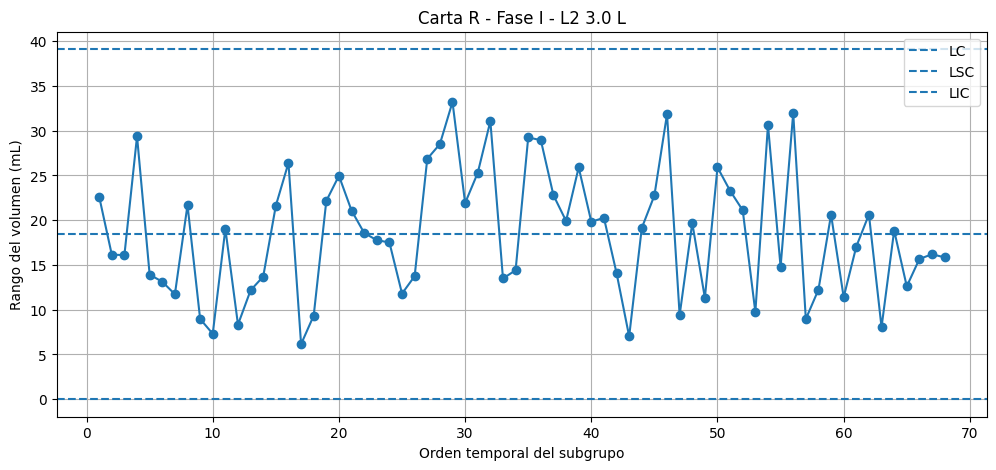

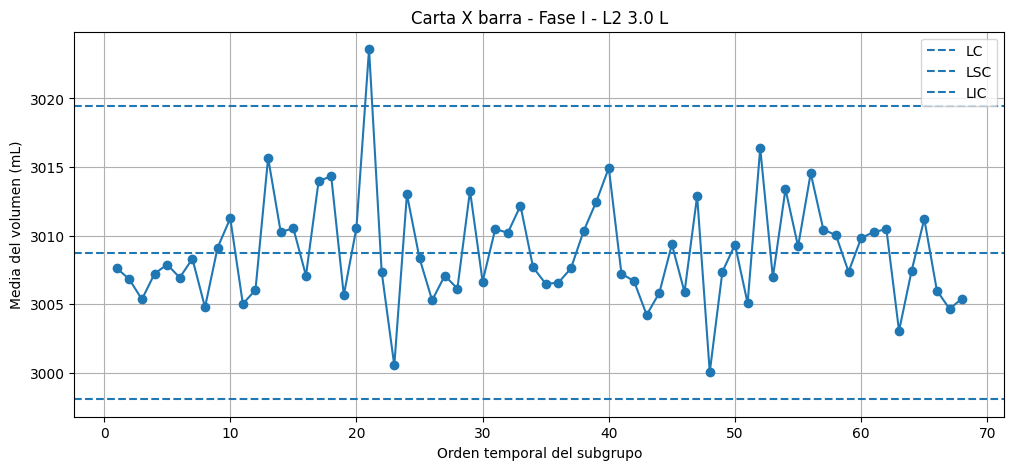

In [30]:
analizar_fase1(datos_control, "L2", 3.0)

Se analizaron los subgrupos identificados mediante las cartas de control y las reglas de Nelson durante la Fase I. Se revisaron sus medias y rangos, junto con las variables fecha, semana, turno, SKU y hora de registro, con el propósito de caracterizar las señales detectadas e identificar posibles asociaciones con las condiciones de operación

In [31]:
# DIAGNÓSTICO DE SEÑALES - L2 3.0 L

# 1. Recuperar los subgrupos de Fase I
fase1_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_30 = fase1_L2_30.sort_values("subgrupo")

# 2. Identificar los subgrupos con señales
subgrupos_senal_30 = [
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

# 3. Recuperar fecha, SKU y hora
info_subgrupo = llenado[
    ["subgrupo", "fecha", "sku", "hora"]
].drop_duplicates()

# 4. Seleccionar solamente los subgrupos señalados
diagnostico_30 = fase1_L2_30[
    fase1_L2_30["subgrupo"].isin(subgrupos_senal_30)
].copy()

# 5. Incorporar la información original
diagnostico_30 = pd.merge(
    diagnostico_30,
    info_subgrupo,
    on="subgrupo",
    how="left"
)

# 6. Mostrar resultados
display(
    diagnostico_30[
        [
            "subgrupo",
            "fecha",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,subgrupo,fecha,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,56,2026-07-22,1,B (14-22),FUN-B30,20:00,3010.568,24.97
1,57,2026-07-22,1,C (22-06),FUN-B30,22:00,3023.588,21.08
2,58,2026-07-22,1,C (22-06),FUN-B30,00:00,3007.366,18.58
3,59,2026-07-22,1,C (22-06),FUN-B30,02:00,3000.548,17.77
4,60,2026-07-22,1,C (22-06),FUN-B30,04:00,3013.016,17.52
5,65,2026-07-23,1,B (14-22),NEC-D30,14:00,3008.356,11.80
6,79,2026-07-24,1,B (14-22),NEC-D30,18:00,3006.496,29.25
7,80,2026-07-24,1,B (14-22),NEC-D30,20:00,3006.574,28.95
8,81,2026-07-24,1,C (22-06),NEC-D30,22:00,3007.624,22.79
9,82,2026-07-24,1,C (22-06),NEC-D30,00:00,3010.328,19.92


Durante la Fase I del proceso L2–3,0 L se identificaron señales de comportamiento no aleatorio tanto en la dispersión como en el nivel medio de llenado.

En la carta R se detectó una tendencia decreciente de seis subgrupos consecutivos, cuyos rangos disminuyeron desde 24,97 hasta 11,80 mL. Esta secuencia comprende principalmente el SKU FUN-B30, finalizando con NEC-D30, por lo que podría estar relacionada con cambios en las condiciones operacionales o en el producto procesado.

En la carta X̄ se identificó al subgrupo 57 con una media de 3.023,588 mL, superior al límite de control de 3.019,435 mL. Además, se detectó una tendencia creciente de seis medias consecutivas, desde 3.006,496 hasta 3.014,944 mL, correspondientes al SKU NEC-D30 durante la semana 1.

Las señales sugieren posibles variaciones asociadas a ajustes del equipo, condiciones de operación o cambios de SKU. Sin embargo, la información disponible no permite establecer una causa asignable definitiva, por lo que las observaciones se conservan y las señales se documentan para su evaluación posterior.

no tenemos evidencia suficiente para afirmar que el proceso estuvo completamente bajo control estadístico durante las semanas 1 y 2


In [32]:
# BLOQUE: RESUMEN DE SEÑALES DETECTADAS EN FASE I

import pandas as pd

# Crear tabla resumen con las señales identificadas

resumen_fase1 = pd.DataFrame({

    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L"
    ],

    "Carta": [
        "R", "R", "X barra", "X barra",
        "R", "X barra", "X barra"
    ],

    "Regla": [
        "Fuera de límites",
        "Fuera de límites",
        "Fuera de límites",
        "Tendencia 6 puntos",
        "Tendencia 6 puntos",
        "Fuera de límites",
        "Tendencia 6 puntos"
    ],

    "Subgrupos": [
        "92",
        "33",
        "129",
        "158, 159, 160, 165, 166, 167",
        "56, 57, 58, 59, 60, 65",
        "57",
        "79, 80, 81, 82, 83, 84"
    ],

    "Posible causa": [
        "Variación puntual del llenado",
        "Dispersión elevada en turno C",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de FUN-B15",
        "Cambio gradual de variabilidad entre SKU",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de NEC-D30"
    ],

    "Causa confirmada": [
        "No", "No", "No", "No",
        "No", "No", "No"
    ],

    "Decisión": [
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar"
    ]
})

display(resumen_fase1)

,Proceso,Carta,Regla,Subgrupos,Posible causa,Causa confirmada,Decisión
0,L1 - 0.5 L,R,Fuera de límites,92,Variación puntual del llenado,No,Conservar y documentar
1,L2 - 1.5 L,R,Fuera de límites,33,Dispersión elevada en turno C,No,Conservar y documentar
2,L2 - 1.5 L,X barra,Fuera de límites,129,Posible ajuste al inicio del turno C,No,Conservar y documentar
3,L2 - 1.5 L,X barra,Tendencia 6 puntos,"158, 159, 160, 165, 166, 167",Posible deriva durante producción de FUN-B15,No,Conservar y documentar
4,L2 - 3.0 L,R,Tendencia 6 puntos,"56, 57, 58, 59, 60, 65",Cambio gradual de variabilidad entre SKU,No,Conservar y documentar
5,L2 - 3.0 L,X barra,Fuera de límites,57,Posible ajuste al inicio del turno C,No,Conservar y documentar
6,L2 - 3.0 L,X barra,Tendencia 6 puntos,"79, 80, 81, 82, 83, 84",Posible deriva durante producción de NEC-D30,No,Conservar y documentar


Se consolidaron las señales identificadas mediante las cartas \(\bar X-R\) y las reglas de Nelson para las tres combinaciones línea–formato. La tabla permite comparar los comportamientos anormales detectados, identificar los subgrupos involucrados y registrar las posibles causas operacionales. Las hipótesis planteadas no se consideran causas asignables confirmadas, por lo que los registros se mantienen en la base original.

Ahora hay que distinguir las señales estadísticas de posibles errores en los datos

In [33]:
# BLOQUE: VERIFICACIÓN DE DATOS EN SUBGRUPOS SEÑALADOS

# Reunir los identificadores de todos los subgrupos señalados
subgrupos_senalados = [
    92, 33, 129,
    158, 159, 160, 165, 166, 167,
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

revision_datos = []

for sg in sorted(set(subgrupos_senalados)):

    datos_sg = llenado[
        llenado["subgrupo"] == sg
    ]

    # Cantidad de mediciones
    cantidad = len(datos_sg)

    # Revisar faltantes
    faltantes = datos_sg.isnull().sum().sum()

    # Revisar observaciones numeradas 1 a 5
    numeracion_correcta = (
        sorted(datos_sg["n_obs"].tolist()) == [1, 2, 3, 4, 5]
    )

    # Revisar consistencia del formato
    formato_correcto = datos_sg["formato_L"].nunique() == 1

    # Revisar volúmenes válidos
    volumen_positivo = (datos_sg["volumen_mL"] > 0).all()

    revision_datos.append({
        "subgrupo": sg,
        "mediciones": cantidad,
        "faltantes": faltantes,
        "numeracion_correcta": numeracion_correcta,
        "formato_consistente": formato_correcto,
        "volumen_positivo": volumen_positivo
    })

tabla_verificacion = pd.DataFrame(revision_datos)

display(tabla_verificacion)

,subgrupo,mediciones,faltantes,numeracion_correcta,formato_consistente,volumen_positivo
0,33,5,0,True,True,True
1,56,5,0,True,True,True
2,57,5,0,True,True,True
3,58,5,0,True,True,True
4,59,5,0,True,True,True
5,60,5,0,True,True,True
6,65,5,0,True,True,True
7,79,5,0,True,True,True
8,80,5,0,True,True,True
9,81,5,0,True,True,True


Verificación de integridad de los subgrupos señalados
Se revisaron las mediciones individuales de los subgrupos que presentaron señales estadísticas durante la Fase I, con el objetivo de identificar posibles problemas de registro, valores faltantes o inconsistencias respecto del formato de envase. Esta revisión permite diferenciar anomalías estadísticas de posibles errores de datos, evitando excluir observaciones válidas sin una justificación técnica.

Ahora nos preguntamos ¿Los subgrupos del turno C presentan, en general, medias o rangos mayores que los otros turnos dentro del mismo proceso?

In [34]:
# BLOQUE: EVALUACIÓN DE POSIBLES CAUSAS - TURNOS

# Seleccionar únicamente Fase I
datos_fase1 = datos_control[
    datos_control["fase"] == "I"
].copy()

# Comparar media y rango por proceso y turno
comparacion_turnos = datos_fase1.groupby(
    ["linea", "formato_L", "turno"]
)[["media_volumen", "rango_volumen"]].agg(
    ["count", "mean"]
)

print("Comparación de procesos según turno:")
display(comparacion_turnos)

Comparación de procesos según turno:


media_volumen              rango_volumen           
                                  count         mean         count       mean
linea formato_L turno                                                        
L1    0.5       A (06-14)            24   502.431750            24   4.237917
                B (14-22)            24   502.855500            24   5.261250
L2    1.5       A (06-14)            28  1503.083500            28  10.247857
                B (14-22)             4  1502.581500             4  14.962500
                C (22-06)            20  1506.754200            20  12.971500
      3.0       A (06-14)            12  3009.026500            12  17.616667
                B (14-22)            36  3007.904389            36  16.690556
                C (22-06)            20  3010.141400            20  22.287000

Una vez verificada la integridad básica de los subgrupos señalados, se procedió a contrastar las anomalías estadísticas con las condiciones de operación. Se analizaron las diferencias en el nivel medio y la dispersión del volumen según línea, formato y turno durante la Fase I, con el objetivo de identificar posibles asociaciones entre las señales detectadas y las características del proceso productivo.

Este análisis es exploratorio y permite formular hipótesis operacionales, sin establecer relaciones causales definitivas.

Proceso	Hallazgo principal
L1–0,5 L	El turno B tiene mayor rango promedio (5,26 mL) que A (4,24 mL).
L2–1,5 L	El turno C presenta la media más alta (1.506,75 mL).
L2–3,0 L	El turno C presenta tanto la media más alta (3.010,14 mL) como el rango promedio más alto (22,29 mL).

**DECISION PARA FASE 2!!!!!:**
Después de revisar las anomalías detectadas en los tres procesos, comprobamos que los subgrupos tenían sus cinco mediciones, no presentaban datos faltantes y cumplían las verificaciones básicas realizadas.

Aunque encontramos valores fuera de los límites de control y algunas tendencias, no logramos identificar una causa específica que permitiera justificar la eliminación de esos registros.

Por esta razón, decidimos conservar todos los datos y mantener los límites calculados inicialmente, evitando modificar los resultados sin una justificación.

Sin embargo, como se detectaron señales de comportamiento anormal, todavía no podemos afirmar que los procesos sean completamente estables. Por lo tanto, utilizaremos estos límites de manera provisional para analizar las semanas siguientes (Fase II), dejando constancia de esta limitación.

In [35]:
# BLOQUE: DECISIÓN SOBRE LÍMITES DE FASE I

decision_limites = pd.DataFrame({
    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L"
    ],

    "Subgrupos_Fase_I": [
        48, 52, 68
    ],

    "Causa_asignable_confirmada": [
        "No", "No", "No"
    ],

    "Exclusiones": [
        0, 0, 0
    ],

    "Decision": [
        "Conservar límites preliminares",
        "Conservar límites preliminares",
        "Conservar límites preliminares"
    ],

    "Estado": [
        "Estabilidad no demostrada",
        "Estabilidad no demostrada",
        "Estabilidad no demostrada"
    ]
})

display(decision_limites)

,Proceso,Subgrupos_Fase_I,Causa_asignable_confirmada,Exclusiones,Decision,Estado
0,L1 - 0.5 L,48,No,0,Conservar límites preliminares,Estabilidad no demostrada
1,L2 - 1.5 L,52,No,0,Conservar límites preliminares,Estabilidad no demostrada
2,L2 - 3.0 L,68,No,0,Conservar límites preliminares,Estabilidad no demostrada


**PREPARACION FASE 2**
Para saber:
Fase I (semanas 1 y 2): calculamos límites, detectamos anomalías e investigamos posibles causas.
Fase II (semanas 3 a 10): evaluaremos si los nuevos subgrupos presentan señales utilizando los mismos límites.


In [36]:
#PREPARACIÓN FASE 2
# BLOQUE: GUARDAR LÍMITES DE FASE I

# Constantes para subgrupos de 5 botellas
A2 = 0.577
D3 = 0
D4 = 2.114

limites_fase1 = []

# Procesos que estamos analizando
procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

for linea, formato in procesos:

    # Seleccionar únicamente los subgrupos de Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ]

    # Promedio de medias y rangos
    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Guardar límites de ambas cartas
    limites_fase1.append({
        "linea": linea,
        "formato_L": formato,
        "LIC_R": D3 * media_rangos,
        "LC_R": media_rangos,
        "LSC_R": D4 * media_rangos,
        "LIC_X": media_medias - A2 * media_rangos,
        "LC_X": media_medias,
        "LSC_X": media_medias + A2 * media_rangos
    })

limites_fase1 = pd.DataFrame(limites_fase1)

display(limites_fase1.round(3))

,linea,formato_L,LIC_R,LC_R,LSC_R,LIC_X,LC_X,LSC_X
0,L1,0.5,0.0,4.750,10.041,499.903,502.644,505.384
1,L2,1.5,0.0,11.658,24.645,1497.730,1504.457,1511.183
2,L2,3.0,0.0,18.500,39.109,2998.086,3008.760,3019.435


Preparación de la Fase II

Para evaluar el comportamiento del llenado durante las semanas 3 a 10, se utilizarán los límites preliminares obtenidos en Fase I (semanas 1 y 2). Estos límites se mantendrán constantes durante el monitoreo, evitando recalcularlos con las nuevas observaciones.

Debido a las señales detectadas durante Fase I, los resultados de Fase II se interpretarán como una evaluación provisional del proceso.

In [37]:
# BLOQUE: SELECCIÓN DE DATOS PARA FASE II

fase2 = datos_control[
    datos_control["fase"] == "II"
].copy()

# Revisar cantidad total de subgrupos
print("Total de subgrupos en Fase II:")
print(fase2.shape[0])

# Revisar distribución por proceso
print("\nSubgrupos por línea y formato:")
print(
    fase2.groupby(["linea", "formato_L"]).size()
)

Total de subgrupos en Fase II:
672

Subgrupos por línea y formato:
linea  formato_L
L1     0.5          192
L2     1.5          236
       3.0          244
dtype: int64


Selección de datos para Fase II

Para desarrollar el monitoreo de Fase II se seleccionaron los subgrupos correspondientes a las semanas 3 a 10. Estos datos se evaluarán utilizando los límites preliminares obtenidos durante las semanas 1 y 2, sin modificarlos ni recalcularlos con las nuevas observaciones.

In [40]:
# BLOQUE: CARTAS DE CONTROL - FASE II

import matplotlib.pyplot as plt

def graficar_fase2(linea, formato):

    # Seleccionar el proceso en Fase II
    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ].copy()

    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Recuperar los límites calculados en Fase I
    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    # Graficar ambas cartas
    for variable, nombre, tipo in [
        ("rango_volumen", "R", "R"),
        ("media_volumen", "X barra", "X")
    ]:

        LIC = limites["LIC_" + tipo]
        LC = limites["LC_" + tipo]
        LSC = limites["LSC_" + tipo]

        plt.figure(figsize=(12, 5))

        plt.plot(
            datos["orden"],
            datos[variable],
            marker="o",
            markersize=3
        )

        plt.axhline(LIC, linestyle="--", label="LIC")
        plt.axhline(LC, linestyle="--", label="LC")
        plt.axhline(LSC, linestyle="--", label="LSC")

        plt.xlabel("Orden temporal del subgrupo")
        plt.ylabel("Volumen (mL)" if tipo == "X" else "Rango (mL)")
        plt.title(
            "Carta " + nombre + " - Fase II - " +
            linea + " " + str(formato) + " L"
        )

        plt.legend()
        plt.grid()
        plt.show()


Una vez separados los 672 subgrupos correspondientes a las semanas 3 a 10, se procedió a evaluar su comportamiento mediante cartas R y X̄.

Para ello se utilizaron los límites preliminares calculados en Fase I, manteniéndolos constantes durante todo el monitoreo. El objetivo es identificar posibles cambios en el promedio y la variabilidad del llenado respecto del período inicial.

Debido a que la Fase I presentó señales no resueltas, los resultados se interpretarán de manera provisional.